# JEV / 决策模型（Decision Models）分享演示

**Agent 时代的「快思考」基础设施 —— 现场可运行 Notebook**

本 Notebook 与同目录 `code_doubao/` 下的完整脚本配套（单一代码源），按分享文档章节组织。

- **无需 API Key / GPU**：默认走内置离线 `MockSystemOneClient`，即可端到端跑通三原语、门控降级、菜品匹配、搜索重排、十个场景、Agent 护栏与评测。Mock 只是确定性启发式，**不是模型**，用于看清 schema 与控制流。
- 接本地 Laya（数据不出域）：先 `uvicorn 05_laya_serve:app --port 8000`，再设置 `SYSTEMONE_BASE_URL=http://localhost:8000`。
- 接 JEV 云：设置 `TYPESAFE_API_KEY=...`（中国大陆暂未开放，注意数据合规）。

> 运行顺序：从上到下逐格执行（Shift+Enter）。

In [1]:
import os, sys, importlib.util, json

HERE = os.getcwd()
if HERE not in sys.path:
    sys.path.insert(0, HERE)

from systemone_client import get_client  # noqa: E402

def load(name):
    """按文件名加载同目录下的演示脚本（文件名以数字开头）。"""
    path = os.path.join(HERE, name + '.py')
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    sys.modules[name] = mod  # 关键：注册后 dataclass 的字符串注解才能解析
    spec.loader.exec_module(mod)
    return mod

client = get_client()
print('后端 =', client.__class__.__name__, '（MockSystemOneClient 表示未配置真实 Key，走离线模拟）')

后端 = MockSystemOneClient （MockSystemOneClient 表示未配置真实 Key，走离线模拟）


## ① 三原语：Choice / Score / Noul（文档 1.2）

同一个 `state`，一次调用并行提出三种结构化问题，返回可直接 `if/else` 的结果。

In [2]:
state = '用户说：我被重复扣款了，请立刻退款，这已经是本月第二次了。'
questions = {
    'refund':     {'type': 'noul',   'instructions': '用户是否明确要求退款？'},
    'department': {'type': 'choice', 'instructions': '这张工单应分给哪个团队？',
                   'criteria': {'billing': '账单、发票、退款、重复扣款',
                                'tech': '技术故障、bug、宕机',
                                'sales': '新购、续费、报价',
                                'other': '以上都不是'}},
    'urgency':    {'type': 'score',  'instructions': '这件事的紧急程度？',
                   'criteria': ['不急', '一般', '较急', '紧急', '非常紧急']},
}
resp = client.ask(state, questions)
print(json.dumps(resp['answers'], ensure_ascii=False, indent=2))

{
  "refund": {
    "type": "noul",
    "noul": 0.936
  },
  "department": {
    "type": "choice",
    "choice": "billing",
    "probabilities": {
      "billing": 0.854,
      "tech": 0.047,
      "sales": 0.048,
      "other": 0.051
    },
    "confidence": 0.854
  },
  "urgency": {
    "type": "score",
    "score": 4.0,
    "distribution": {
      "3": 0.0,
      "4": 1.0
    },
    "confidence": 0.95
  }
}


## ② 批量并行：state 只传一次（文档 1.3.3 / 1.4）

把多个判断打包进一次调用，通过 packing + tree mask 在一次前向里给所有候选打分。

In [3]:
load('02_batch_parallel').main()

[backend] MockSystemOneClient

== 批量并行（1 次调用，6 个问题）==
  [0] -> billing  conf=0.64  您的发票已出具，请查收附件。
  [1] -> spam     conf=0.639 限时免费领取会员！点击链接立即激活。
  [2] -> tech     conf=0.637 生产环境数据库连接超时，订单服务 502，请尽快处理。
  [3] -> sales    conf=0.634 新版本企业套餐上线，需要我给您报价吗？
  [4] -> hr       conf=0.629 请于周五前补充入职材料并回传身份证复印件。
  [5] -> billing  conf=0.631 我上周申请的退款至今没有到账，请帮忙催一下。
  耗时(含 Mock 处理): 2.09 ms

== 顺序调用（6 次调用）==
  耗时(含 Mock 处理): 1.37 ms
  本地 Mock 墙钟倍速 ≈ 0.7× （真实模型上官方口径约 10×，且 state 只传一次，省输入 token）

== 输入 token 建模（state=2000, 每问题=40）==
  顺序 12240 vs 批量 2240，输入放大约 5.5×


## ③ 置信度门控 + LLM/人工降级（文档 3.3）

Noul 接近 0.5 是「拿不准」而不是「否」；低置信一律升级，绝不瞎猜。

In [4]:
load('07_confidence_gate').main()

  state='这笔重复扣款我要求立刻退款。'           type=noul    -> yes       0.924
  state='今天天气不错，想问问营业时间。'          type=noul    -> no        0.094
  state='服务器一直返回 502，订单下不了。'       type=choice  -> choice    tech


## ④ 菜品匹配 POC（文档 3.2.2）

Noul 判等（is A==B）+ Choice 标准菜名归属 + Score 相似度分级，置信度驱动自动合并 / 升级 / 判新。

In [5]:
load('08_dish_matching').main()

== ① 判等 Noul + 置信度分流 ==
  ✓ 宫保鸡丁     ~ 宫爆鸡丁     p=0.96   -> AUTO_MERGE  真值=1 (错别字等价)
  ·升级 西红柿炒鸡蛋   ~ 番茄炒蛋     p=0.705  -> LLM_REVIEW  真值=1 (别名等价)
  ✓ 麻婆豆腐     ~ 麻辣豆腐     p=0.96   -> AUTO_MERGE  真值=1 (近义等价)
  ✓ 酸辣土豆丝    ~ 酸辣土豆片    p=0.96   -> AUTO_MERGE  真值=1 (刀工/写法差异)
  ·升级 宫保鸡丁     ~ 辣子鸡      p=0.172  -> LLM_REVIEW  真值=0 (不同菜)
  ·升级 红烧肉      ~ 红烧排骨     p=0.585  -> LLM_REVIEW  真值=0 (主料不同)
  ·升级 鱼香肉丝     ~ 鱼香茄子     p=0.435  -> LLM_REVIEW  真值=0 (主料不同)
  ·升级 水煮鱼      ~ 水煮肉片     p=0.585  -> LLM_REVIEW  真值=0 (主料不同)
  自动判定 3 条，正确率 3/3；其余 5 条进入 LLM/人工复核（不计错，也不自动动作）

== ② 相似度分级 Score ==
  宫保鸡丁 ~ 宫爆鸡丁 -> 相似度分 2.98
  宫保鸡丁 ~ 辣子鸡 -> 相似度分 2.61
  红烧肉 ~ 红烧排骨 -> 相似度分 2.21

== ③ 归属标准菜名 Choice（带 other）==
  宫爆鸡丁             -> 宫保鸡丁     conf=0.28
  番茄炒蛋             -> other    conf=0.093
  麻辣豆腐             -> 麻婆豆腐     conf=0.27
  巴西烤肉汉堡(未知)       -> other    conf=0.087


## ⑤ 搜索相关性 / 重排序过滤层（文档 3.2.1，PPT 场景 07）

让决策模型坐在「检索」与「生成」之间，先过滤无关文档再交给 LLM。

In [6]:
load('09_search_rerank').main()

query = '如何做宫保鸡丁'

  保留 score=2.46 conf=0.824  宫保鸡丁的家常做法与配料表。
  保留 score=2.17 conf=0.756  宫保鸡丁的历史起源、口味特点与小贴士。
  过滤 score=0.29 conf=0.882  鱼香肉丝的正宗做法。
  过滤 score=0.29 conf=0.882  一篇与做菜无关的旅游随笔。
  过滤 score=0.0  conf=0.95  今天股市行情综述与板块点评。

召回 5 -> 保留 2 / 过滤 3，仅把高相关文档送入 LLM。


## ⑥ 高基数 Choice：两阶段（文档 1.2.2）

候选很多时，先独立打分召回 top-k，再在小集合上做显式 choice，避免 softmax 被稀释。

In [7]:
load('10_high_cardinality').main()

用户菜品：宫爆鸡丁
  阶段一 top-k: ['宫保鸡丁', '辣子鸡', '口水鸡', '白切鸡', '宫保虾球']
  阶段二 choice -> 宫保鸡丁 (conf=0.393)

用户菜品：番茄炒蛋
  阶段一 top-k: ['番茄炒蛋', '西红柿炒鸡蛋', '鱼香茄子', '鱼香烘蛋', '宫保鸡丁']
  阶段二 choice -> 番茄炒蛋 (conf=0.79)

用户菜品：麻辣豆腐
  阶段一 top-k: ['麻辣豆腐', '麻婆豆腐', '宫保豆腐', '酸辣土豆丝', '辣子鸡']
  阶段二 choice -> 麻辣豆腐 (conf=0.66)

用户菜品：黄焖鸡
  阶段一 top-k: ['黄焖鸡米饭', '辣子鸡', '口水鸡', '白切鸡', '宫保鸡丁']
  阶段二 choice -> 黄焖鸡米饭 (conf=0.441)



## ⑦ 十个使用场景（文档 3.2.3，综合自组内 PPT）

收件箱分类、关键词意图、线索评分、模型路由、上下文压缩、浏览器动作、搜索重排、发布红绿灯、护栏、工单分流。

In [8]:
load('14_ten_use_cases').main()

[backend] MockSystemOneClient

[01 收件箱分类]
   billing  您的发票已出具，请查收。
   spam     限时免费领取会员，点击激活！
   tech     生产库连接超时，订单 502。
   hr       请周五前补交入职材料。

[02 关键词意图]
   informational  宫保鸡丁的做法
   commercial     蓝牙耳机哪款好
   transactional  iphone17 官网下单
   informational  什么是决策模型
   transactional  云服务器优惠购买
   commercial     机械键盘 推荐 对比

[03 销售线索评分]
   强度=1.7  fit_p=0.9   话术匹配  某电商 CTO，明确说本月要
   强度=0.24  fit_p=0.1   ❲话术不匹配，需重写❳  只是学生，留言说想了解概念
   强度=1.7  fit_p=0.9   话术匹配  中型搜索团队负责人，抱怨 L

[04 模型路由]
   -> cheap     把这句翻译成英文
   -> flagship  设计高并发交易系统的限流与对账方案

[05 上下文压缩] 保留 2/4 条：['支付服务日志：db 连接池打满导致 502', '连接池 max_connections=10 已打满']

[06 浏览器操作选择]（模拟 computer-use 循环）
   观察→ click_origin（执行后把新页面状态再交回决策模型）
   观察→ click_dest（执行后把新页面状态再交回决策模型）
   观察→ click_search（执行后把新页面状态再交回决策模型）

[07 搜索重排序]
   score=3.0 宫保鸡丁家常做法与配料。
   score=2.56 宫保鸡丁起源与口味。
   score=0.0 今日股市行情。

[08 发布红绿灯]
   🟢 放行  intent=0.71 unsourced=0.12 links=0.95  如何做宫保鸡丁
   🔴 退回  intent=0.15 unsourced=0.88 links=0.95  2026 年决策模型盘点

[09 智能体护栏]
   ✅放行

## ⑧ Agent 工具安全门 + 完成验证（文档 3.2.4，PPT 场景 09）

In [9]:
load('11_agent_guardrail').main()

== 正常：删除测试环境临时文件 ==
  ✅ 放行 fs.rm temp.log（safe_p=0.9）→ 执行
     完成验证 done_p=0.9 -> 达成

== 危险：删除生产数据库（应被阻断）==
  🛑 阻断 db.drop production（safe_p=0.08 < 0.8）→ 转人工确认

== 越权：未经确认的大额转账（应被阻断）==
  🛑 阻断 pay.transfer 50000（safe_p=0.08 < 0.8）→ 转人工确认


## ⑨ 编码 Agent 上下文压缩（PPT 场景 05）

In [10]:
load('12_context_compression').main()

当前目标：修复支付接口的 502 错误

保留 4 条：
  keep p=0.9   (tool) GET /health 返回 200，所有服务正常。
  keep p=0.9   (tool) 支付服务日志：上游超时导致 502，错误集中在 db 连接池。
  keep p=0.9   (tool) db 连接池配置 max_connections=10，当前已打满。
  keep p=0.9   (assistant) 已确认根因：连接池过小，调大到 50 并加重试。

压缩 2 条：
  drop p=0.12  (user) 顺便问下今天北京天气怎么样？
  drop p=0.12  (tool) 三年前的一次无关部署记录。

上下文 token：约 217 -> 169（下降 22%）。


## ⑩ 模型 / 工具路由与成本账本（PPT 场景 04）

In [11]:
load('13_model_router').main()

== 路由结果 ==
  [cheap   ] conf=0.82  把这句话翻译成英文：今天开会。
  [cheap   ] conf=0.82  给这段文字挑错别字。
  [balanced] conf=0.82  帮我写一个正则匹配手机号。
  [balanced] conf=0.82  总结这篇 2000 字文章的三个要点。
  [balanced] conf=0.82  解释一下什么是闭包，并举个例子。
  [flagship] conf=0.82  排查这个分布式系统偶发死锁的根因并给出修复方案。
  [flagship] conf=0.82  为高并发交易系统设计一套限流+降级+对账方案。
  [cheap   ] conf=0.82  把客户姓名按拼音首字母排序。
  [cheap   ] conf=0.82  判断这条评论是正面还是负面。
  [flagship] conf=0.82  从这段堆栈定位空指针并修改代码。
  [cheap   ] conf=0.82  写一首关于春天的短诗。
  [flagship] conf=0.82  推导这个概率题并给出严格证明。

== 成本账本（建模）==
  全部走旗舰       : $0.0072
  路由后混合档位   : $0.0029（仅 4/12 条走旗舰）
  相比全旗舰节省   : 60%
  （对照：全走最便宜档 $0.0002，但难任务质量无保障）


## ⑪ 评测四维：准确率 / 底线率 / Brier / ECE（文档 3.4）

不只看准确率，还要看校准。下图对比「校准良好的决策模型」与「过度自信的 LLM 式概率」。

--- 决策模型（校准良好） ---
  样本 N=600
  准确率 Accuracy = 0.717
  底线率 Baseline = 0.833（需降级/转人工比例）
  Brier           = 0.184（越小越好）
  ECE             = 0.044（越小越校准）
  可靠性分桶 (预测概率 -> 真实正例率, n):
    0.05 -> 0.08  (n=53)
    0.15 -> 0.20  (n=70)
    0.26 -> 0.32  (n=59)
    0.35 -> 0.32  (n=56)
    0.44 -> 0.54  (n=61)
    0.55 -> 0.53  (n=66)
    0.65 -> 0.65  (n=65)
    0.75 -> 0.81  (n=68)
    0.85 -> 0.80  (n=55)
    0.95 -> 0.91  (n=47)

--- LLM 式（过度自信，对照） ---
  样本 N=600
  准确率 Accuracy = 0.737
  底线率 Baseline = 0.518（需降级/转人工比例）
  Brier           = 0.197（越小越好）
  ECE             = 0.118（越小越校准）
  可靠性分桶 (预测概率 -> 真实正例率, n):
    0.04 -> 0.16  (n=148)
    0.14 -> 0.36  (n=59)
    0.25 -> 0.39  (n=31)
    0.35 -> 0.41  (n=32)
    0.45 -> 0.42  (n=31)
    0.55 -> 0.62  (n=24)
    0.66 -> 0.69  (n=36)
    0.75 -> 0.55  (n=42)
    0.85 -> 0.77  (n=56)
    0.95 -> 0.84  (n=141)

注：上方为 600 条模拟样本，用于讲清指标；真实评测请把
    synthetic_predictions 换成对 client 的循环调用，评测集模板见 EVAL_SET。


校准曲线图已保存：D:\work\滴滴\share\Jev\images\calibration_reliability.png

纪律：四项齐报、无重试无回退、预算记账；在自己的中文集上 A/B，勿直接引用厂商榜单。


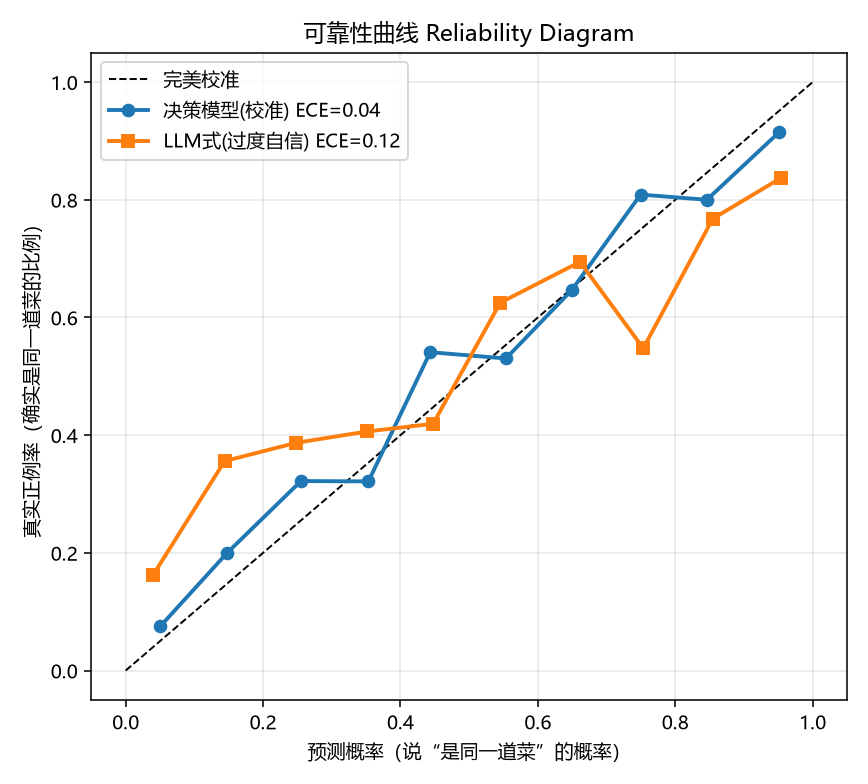

In [12]:
load('15_eval').main()
from IPython.display import Image, display
display(Image(filename=os.path.join(HERE, '..', 'images', 'calibration_reliability.png')))

## ⑫ 阈值选择（jevcal 思路，文档 3.3 / 3.4）

在「自动区间准确率 ≥ 目标」前提下，最小化需要升级 LLM/人工的流量；模型更新跌破目标即让 CI 失败。

In [13]:
load('16_threshold_jevcal').main()

目标：自动处理区间准确率 ≥ 95%，最小化 LLM/人工 流量

   thr         自动区间准确率        LLM/人工流量       自动样本数
 0.500           0.831            0.0%        2000
 0.550           0.882           15.9%        1682
 0.600           0.928           28.8%        1423
 0.650           0.966           40.3%        1193
 0.700           0.978           50.3%         994
 0.750           0.991           60.1%         798
 0.800           0.998           70.7%         586
 0.850           1.000           82.1%         358
 0.900           1.000           91.4%         172
 0.950           1.000           97.3%          54

推荐阈值 thr=0.625：自动区间准确率 0.950，65.5% 流量全自动、仅 34.5% 升级 LLM/人工。

CI 守门（jevcal 做法）：
  1) 把选定 thr 与评测集固化到仓库；
  2) 每次模型/基座更新后重跑本脚本；
  3) 若自动区间准确率跌破目标（如 0.95），让 CI 失败，阻止静默上线。


## ⑬ 成本与批量并行配图（文档 1.4）

== 单次决策成本对比（输出 token：JEV 免费 / LLM 计费）==

场景                                         JEV       Luna短标签       Luna带推理
每千次·2000 输入·轻量判断                         0.084         0.212         0.400
每千次·5000 输入·中等工单                         0.210         0.512         0.700
每天 1 亿次判断（2000 输入）                    8400.000     21200.000     40000.000

== 大纲给定对照（每 1000 次、各 2000 输入）==
  JEV ≈ $0.084；GPT-6 Luna 短标签 ≈ $0.215；带 ~500 推理 ≈ $0.465
  → 同样判断，JEV 比“带推理 LLM”便宜约 5.5×。

== 批量并行（13 个问题）成本直觉 ==
  顺序输入 26520 token，批量输入 2520 token，省输入 90.5%（官方口径成本约降 12.2×、速度约快 10×*）

* 带星号/“官方口径”的数字为厂商自报上限，非典型生产值，引用请注明。


saved: D:\work\滴滴\share\Jev\images\cost_comparison.png


saved: D:\work\滴滴\share\Jev\images\batch_savings.png


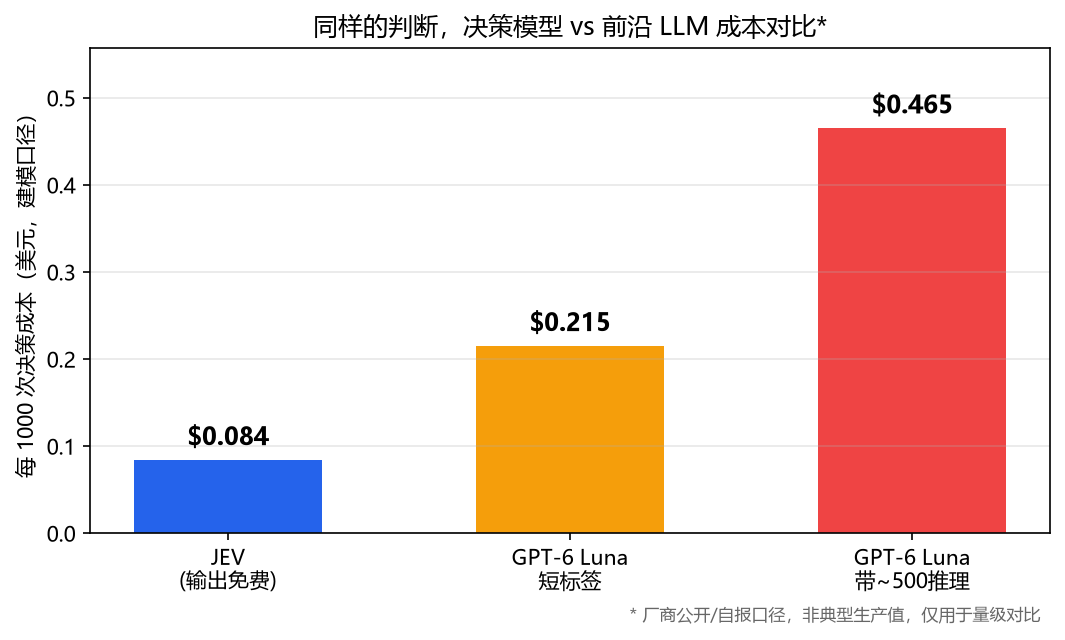

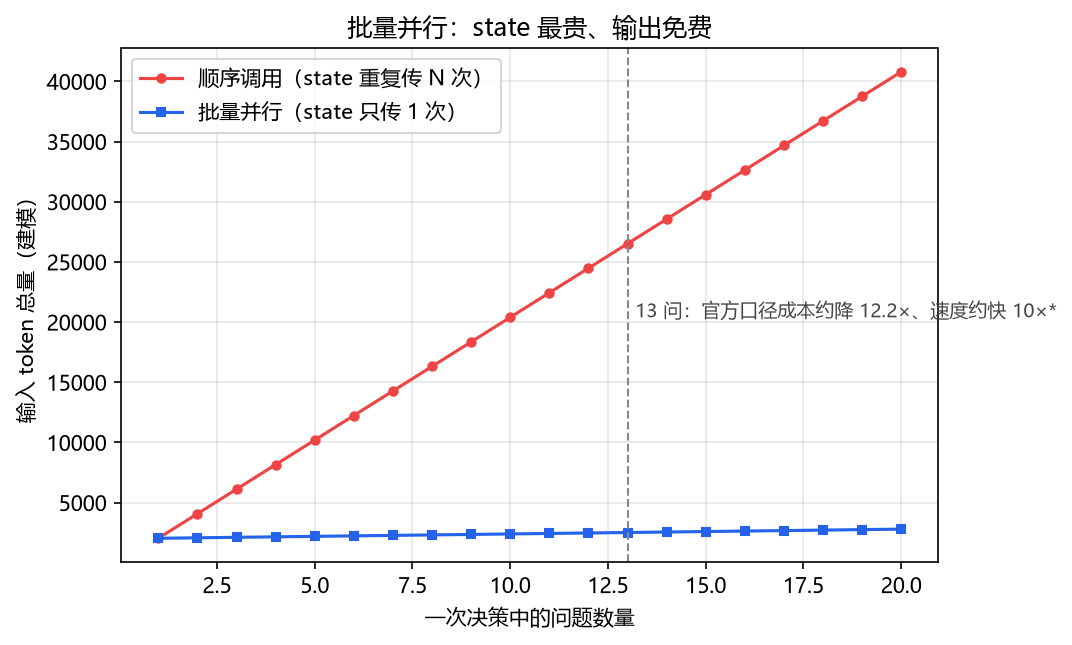

In [14]:
load('03_cost_model').main()
load('make_figures').fig_cost()
load('make_figures').fig_batch()
display(Image(filename=os.path.join(HERE, '..', 'images', 'cost_comparison.png')))
display(Image(filename=os.path.join(HERE, '..', 'images', 'batch_savings.png')))

## 落地与私有化（文档 2.4 / 3.x）

- **本地 Laya 推理**：`04_laya_local.py`（MLX / PyTorch / Mock 三回退），中文优先 `laya-multilingual`。
- **服务化**：`05_laya_serve.py` 起 FastAPI，暴露与 JEV 同格式的 `POST /v1/systemone`，业务侧零改造切换。
- **RLCD 微调**：`06_finetune_laya.py` 生成领域决策数据集（`dish_match.jsonl` / `search_relevance.jsonl`），流程见 `06_finetune_laya.md`；微调后务必重画可靠性曲线、重选阈值。
- **灰度**：shadow（并跑比对）→ canary（小流量高置信自动）→ enforce（高置信自动、中置信升级、低置信转人工）。

**收尾结论**：决策模型不是「会思考的聊天模型」，而是 Agent 架构里廉价、高频、可校准的「判断层」——系统二负责想，系统一负责判，Harness 负责调度。